# Feature Engineering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime, timezone
from dateutil.relativedelta import relativedelta 
from zoneinfo import ZoneInfo
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

import database

In [2]:
SERIES_IDS = ['UNRATE', 'INDPRO', 'JTSJOL']

## Import raw feature data from the db

In [3]:
data = database.db_requester_fetchall(sql_script="all_obs_FREDObservations.sql")

In [4]:
arr_raw = np.array(data)
arr_raw[np.where(arr_raw == None)[0]]
# np.isnan(arr_raw)

array([['UNRATE', '2025-10-01', None, '2026-09-05 13:25:20']],
      dtype=object)

## Data prep
- Impute missing values

In [5]:
df_raw = pd.DataFrame(data, columns=['series_id', 'year_month', 'value', 'timestamp'])
df_raw['year_month'] = pd.to_datetime(df_raw['year_month'])
df_raw

,series_id,year_month,value,timestamp
0,UNRATE,2000-12-01,3.9000,2026-09-05 13:25:20
1,UNRATE,2001-01-01,4.2000,2026-09-05 13:25:20
2,UNRATE,2001-02-01,4.2000,2026-09-05 13:25:20
3,UNRATE,2001-03-01,4.3000,2026-09-05 13:25:20
4,UNRATE,2001-04-01,4.4000,2026-09-05 13:25:20
...,...,...,...,...
922,JTSJOL,2026-06-01,7182.0000,2026-09-05 13:25:20
923,JTSJOL,2026-07-01,7271.0000,2026-09-05 13:25:20
924,UNRATE,2026-08-01,4.1000,2026-09-05 13:25:20
925,UNRATE,2000-11-01,3.9000,2026-09-05 13:25:20


In [6]:
df = df_raw.pivot(
    index='year_month',
    columns='series_id',
    values='value'
).reset_index()
df['year_month'] = df['year_month'].dt.to_period('M')
df.columns.name = None

df

,year_month,INDPRO,JTSJOL,UNRATE
0,2000-11,92.6438,NaN,3.9
1,2000-12,92.3415,5088.0,3.9
2,2001-01,91.9020,5234.0,4.2
3,2001-02,91.3034,5097.0,4.2
4,2001-03,91.1162,4762.0,4.3
...,...,...,...,...
305,2026-04,102.5198,7585.0,4.3
306,2026-05,102.5099,7537.0,4.3
307,2026-06,102.7868,7182.0,4.2
308,2026-07,102.9939,7271.0,4.1


In [7]:
df[df.isna().any(axis=1)]

,year_month,INDPRO,JTSJOL,UNRATE
0,2000-11,92.6438,NaN,3.9
299,2025-10,101.2195,7170.0,NaN
309,2026-08,NaN,NaN,4.1


In [8]:
df_imputed = df.copy()
df_imputed[SERIES_IDS] = df[SERIES_IDS].interpolate(method="linear")
df_imputed[df_imputed.isna().any(axis=1)]
df_imputed

,year_month,INDPRO,JTSJOL,UNRATE
0,2000-11,92.6438,NaN,3.9
1,2000-12,92.3415,5088.0,3.9
2,2001-01,91.9020,5234.0,4.2
3,2001-02,91.3034,5097.0,4.2
4,2001-03,91.1162,4762.0,4.3
...,...,...,...,...
305,2026-04,102.5198,7585.0,4.3
306,2026-05,102.5099,7537.0,4.3
307,2026-06,102.7868,7182.0,4.2
308,2026-07,102.9939,7271.0,4.1


## Create a features df
If the most recent available `UNRATE` if of time $t$, then the values of `INDPRO` and `JTSJOL` are of time $t-1$

In [9]:
df_features = pd.DataFrame({
    "year_month_t": df_imputed['year_month'].copy(),
    "log_10_UNRATE_t": df_imputed['UNRATE'].apply(np.log10).copy(),
    "log_10_INDPRO_t-1": df_imputed['INDPRO'].shift(1).apply(np.log10).copy(),
    "log_10_JTSJOL_t-1": df_imputed['JTSJOL'].shift(1).apply(np.log10).copy(),
    "UNRATE_t": df_imputed['UNRATE'].copy(),
    "INDPRO_t-1": df_imputed['INDPRO'].shift(1).copy(),
    "JTSJOL_t-1": df_imputed['JTSJOL'].shift(1).copy(),
    "UNRATE_t+1": df_imputed['UNRATE'].shift(-1).copy(),
})

df_features


,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2000-11,0.591065,NaN,NaN,3.9,NaN,NaN,3.9
1,2000-12,0.591065,1.966816,NaN,3.9,92.6438,NaN,4.2
2,2001-01,0.623249,1.965397,3.706547,4.2,92.3415,5088.0,4.2
3,2001-02,0.623249,1.963325,3.718834,4.2,91.9020,5234.0,4.3
4,2001-03,0.633468,1.960487,3.707315,4.3,91.3034,5097.0,4.4
...,...,...,...,...,...,...,...,...
305,2026-04,0.633468,2.007553,3.838030,4.3,101.7543,6887.0,4.3
306,2026-05,0.633468,2.010808,3.879956,4.3,102.5198,7585.0,4.2
307,2026-06,0.623249,2.010766,3.877199,4.2,102.5099,7537.0,4.1
308,2026-07,0.612784,2.011937,3.856245,4.1,102.7868,7182.0,4.1


In [10]:
features = df_features.iloc[:, 1:-1].columns.to_list()
target = "UNRATE_t+1"

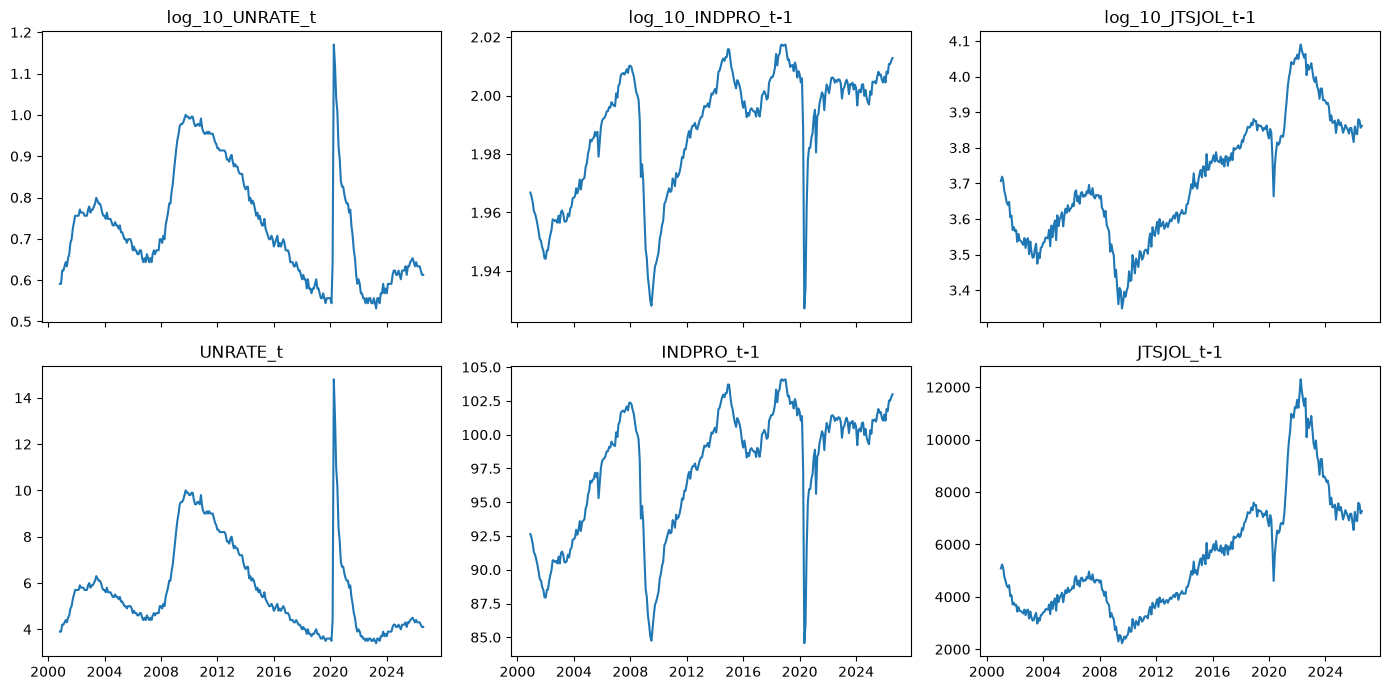

In [11]:
cols_set = df_features.iloc[:, 1:-1].columns.to_list()

ncols = 3
nrows = int(np.ceil(len(cols_set) / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 3.5 * nrows),
    sharex=True
)

# Makes this work whether you have 1 row or multiple rows
axes = np.array(axes).flatten()

for ax, col in zip(axes, cols_set):
    sns.lineplot(
        data=df_features,
        x=df_features['year_month_t'].dt.to_timestamp(),
        y=col,
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(cols_set):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Changes set is more stable**

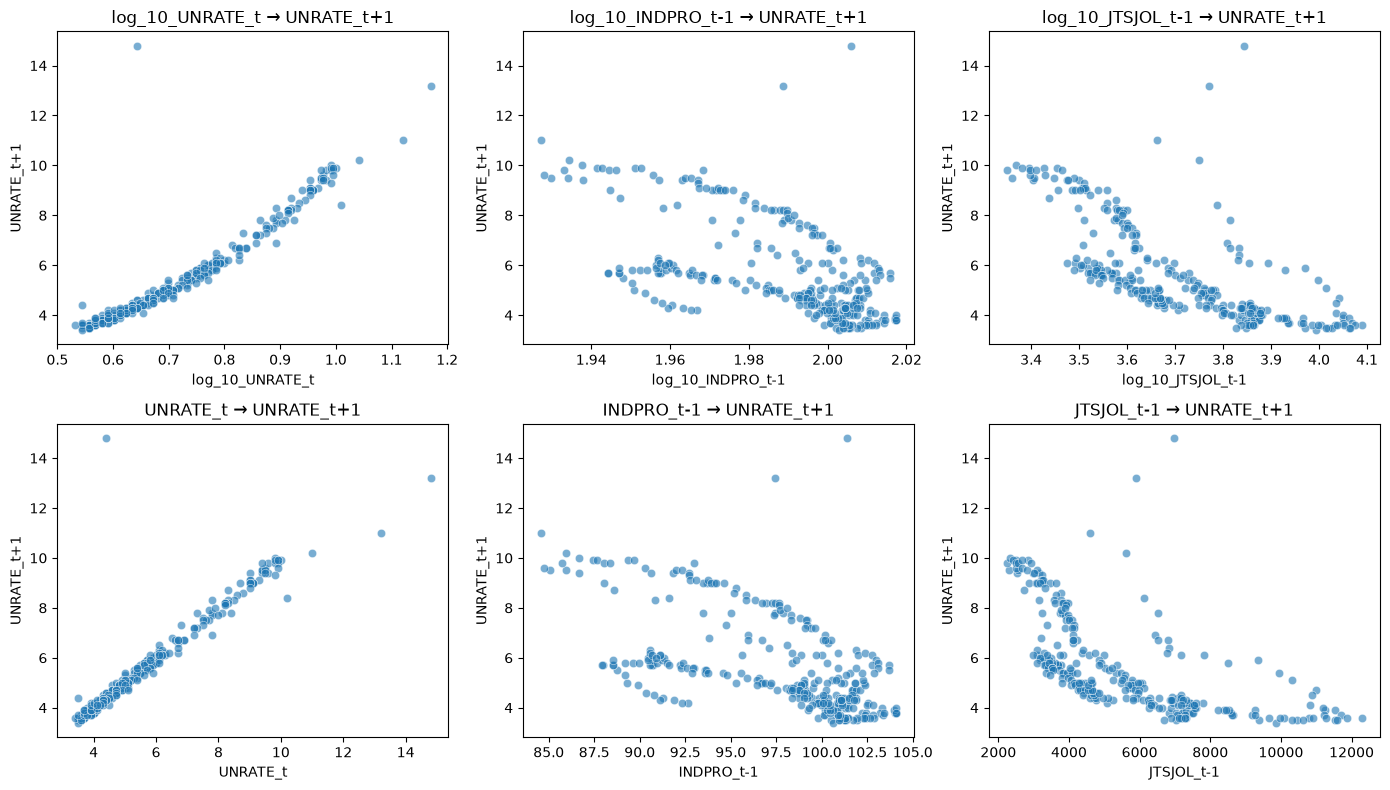

In [12]:
ncols = 3
nrows = int(np.ceil(len(features) / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 4 * nrows)
)

axes = np.array(axes).flatten()

for ax, feature in zip(axes, features):
    sns.scatterplot(
        data=df_features,
        x=feature,
        y=target,
        ax=ax,
        alpha=0.6
    )

    ax.set_title(f"{feature} → {target}")
    ax.set_xlabel(feature)
    ax.set_ylabel(target)


for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

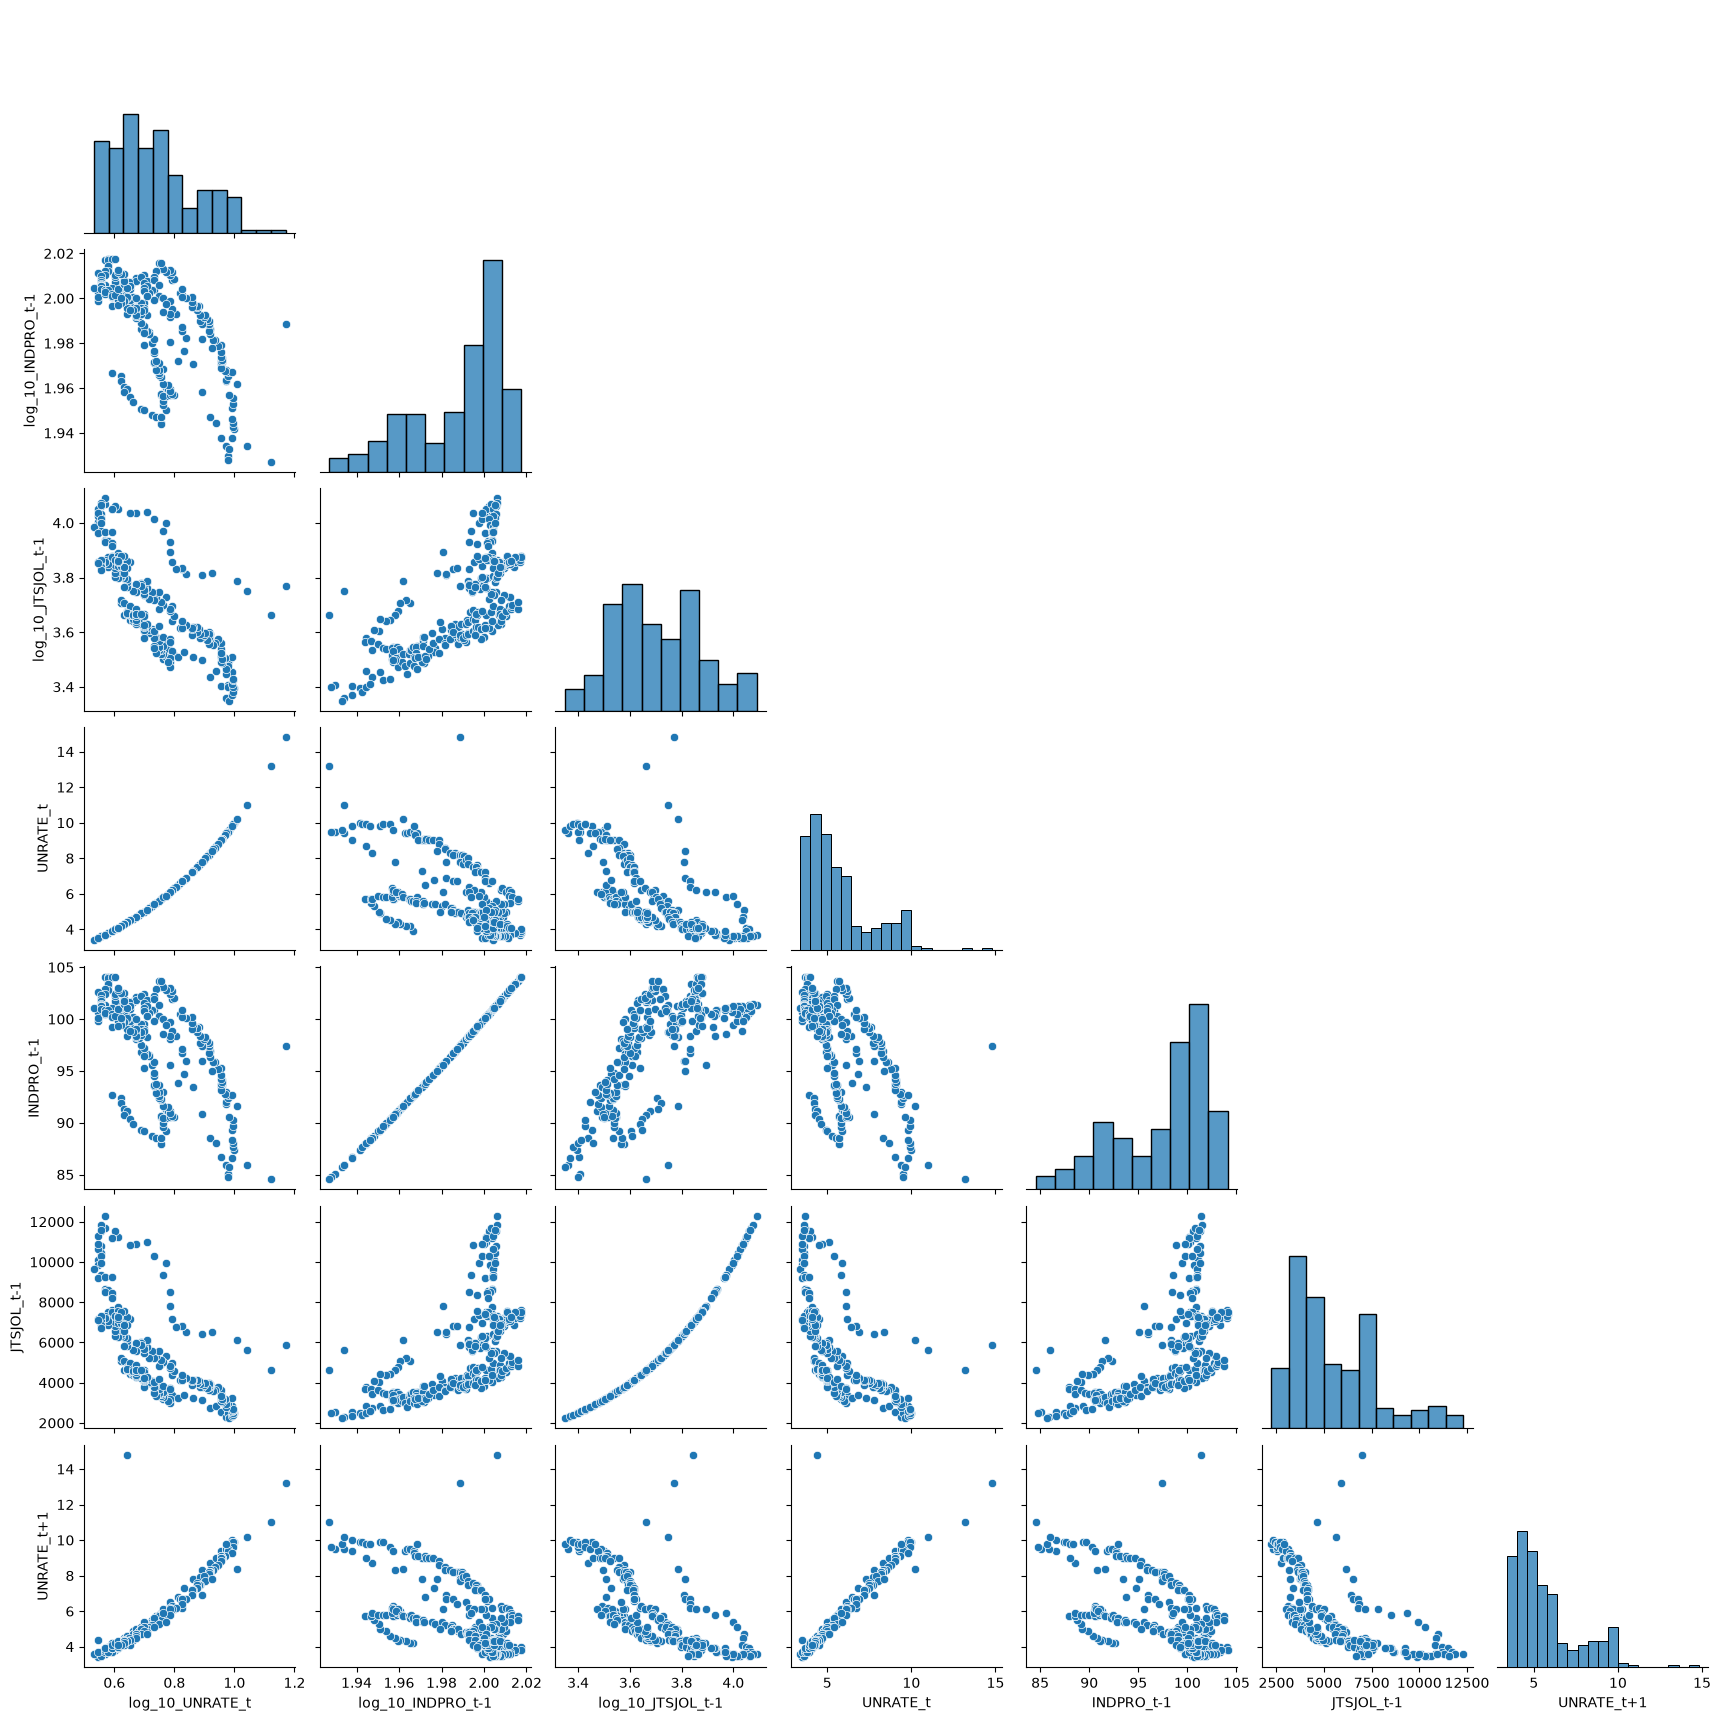

In [13]:
sns.pairplot(
    df_features[features + [target]],
    diag_kind="hist",
    corner=True
)

plt.show()

In [14]:
df_features[features + [target]].corr()

,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
log_10_UNRATE_t,1.000000,-0.621518,-0.742547,0.984922,-0.623726,-0.688645,0.936634
log_10_INDPRO_t-1,-0.621518,1.000000,0.702608,-0.609488,0.999715,0.611356,-0.589738
log_10_JTSJOL_t-1,-0.742547,0.702608,1.000000,-0.680238,0.704636,0.977581,-0.682087
UNRATE_t,0.984922,-0.609488,-0.680238,1.000000,-0.610300,-0.618496,0.944309
INDPRO_t-1,-0.623726,0.999715,0.704636,-0.610300,1.000000,0.613945,-0.590429
JTSJOL_t-1,-0.688645,0.611356,0.977581,-0.618496,0.613945,1.000000,-0.620240
UNRATE_t+1,0.936634,-0.589738,-0.682087,0.944309,-0.590429,-0.620240,1.000000


In [15]:
df_features[df_features.isna().any(axis=1)]

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2000-11,0.591065,NaN,NaN,3.9,NaN,NaN,3.9
1,2000-12,0.591065,1.966816,NaN,3.9,92.6438,NaN,4.2
309,2026-08,0.612784,2.012812,3.861594,4.1,102.9939,7271.0,NaN


# Export the features and target as a df
Implement a fail-safe to ensure that the last month included has complete features or is excluded ('log_10_UNRATE_t', 'log_10_INDPRO_t-1','log_10_JTSJOL_t-1', 'UNRATE_t', 'INDPRO_t-1', 'JTSJOL_t-1')

In [16]:
# # manipulate df with missing values for testing
# df_features.loc[df_features.index[-1], ['log_10_UNRATE_t', 'UNRATE_t']] = np.nan
# df_features.loc[df_features.index[-2], ['UNRATE_t+1']] = np.nan
# df_features

In [17]:
# get the indexes of row with NaN values, excluding the target column UNRATE_t+1 which naturally has a NaN in its last row.
nan_rows = df_features[df_features.iloc[:,1:-2].isna().any(axis=1)].index.to_list()
df_features = df_features.drop(nan_rows, axis=0).reset_index(drop=True)
df_features

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2001-01,0.623249,1.965397,3.706547,4.2,92.3415,5088.0,4.2
1,2001-02,0.623249,1.963325,3.718834,4.2,91.9020,5234.0,4.3
2,2001-03,0.633468,1.960487,3.707315,4.3,91.3034,5097.0,4.4
3,2001-04,0.643453,1.959596,3.677789,4.4,91.1162,4762.0,4.3
4,2001-05,0.633468,1.958034,3.664172,4.3,90.7891,4615.0,4.5
...,...,...,...,...,...,...,...,...
303,2026-04,0.633468,2.007553,3.838030,4.3,101.7543,6887.0,4.3
304,2026-05,0.633468,2.010808,3.879956,4.3,102.5198,7585.0,4.2
305,2026-06,0.623249,2.010766,3.877199,4.2,102.5099,7537.0,4.1
306,2026-07,0.612784,2.011937,3.856245,4.1,102.7868,7182.0,4.1


In [19]:
import feature_pipeline

feature_pipeline.get_features()

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2001-01,0.623249,1.965397,3.706547,4.2,92.3415,5088.0,4.2
1,2001-02,0.623249,1.963325,3.718834,4.2,91.9020,5234.0,4.3
2,2001-03,0.633468,1.960487,3.707315,4.3,91.3034,5097.0,4.4
3,2001-04,0.643453,1.959596,3.677789,4.4,91.1162,4762.0,4.3
4,2001-05,0.633468,1.958034,3.664172,4.3,90.7891,4615.0,4.5
...,...,...,...,...,...,...,...,...
303,2026-04,0.633468,2.007553,3.838030,4.3,101.7543,6887.0,4.3
304,2026-05,0.633468,2.010808,3.879956,4.3,102.5198,7585.0,4.2
305,2026-06,0.623249,2.010766,3.877199,4.2,102.5099,7537.0,4.1
306,2026-07,0.612784,2.011937,3.856245,4.1,102.7868,7182.0,4.1
